<a href="https://colab.research.google.com/github/PYMaksim/LLM-Cost-Context-Simulation-Insights/blob/main/%D0%A1ost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
def request_cost(prompt_tokens, completion_tokens,
                 price_in_per_k, price_out_per_k):
    """Cost of one request in $. Prices are per 1K tokens."""
    return (prompt_tokens / 1000 * price_in_per_k
            + completion_tokens / 1000 * price_out_per_k)

In [2]:
# Prices per 1K tokens ($/1M divided by 1000)
models = {
    "Gemini 2.0 Flash": (0.10/1000, 0.40/1000),
    "GPT-4o mini":      (0.15/1000, 0.60/1000),
    "GPT-5.4 Nano":     (0.20/1000, 1.25/1000),
    "Claude Haiku 4.5": (1.00/1000, 5.00/1000),
}

In [3]:
# 100 requests: prompt=500, output=300 tokens each
for name, (pi, po) in models.items():
    total = 100 * request_cost(500, 300, pi, po)
    print(f"{name}: ${total:.4f}")

Gemini 2.0 Flash: $0.0170
GPT-4o mini: $0.0255
GPT-5.4 Nano: $0.0475
Claude Haiku 4.5: $0.2000


In [4]:
# Chat: history grows, full history is resent each turn
system, user_msg, bot_msg = 100, 200, 300
for name, (pi, po) in models.items():
    cum = 0.0
    for turn in range(1, 11):
        # input = system + history + new message
        inp = system + (turn - 1) * (user_msg + bot_msg) + user_msg
        c = request_cost(inp, bot_msg, pi, po)
        cum += c
        print(f"{name} turn {turn}: input={inp}, ${c:.6f}, total=${cum:.6f}")

Gemini 2.0 Flash turn 1: input=300, $0.000150, total=$0.000150
Gemini 2.0 Flash turn 2: input=800, $0.000200, total=$0.000350
Gemini 2.0 Flash turn 3: input=1300, $0.000250, total=$0.000600
Gemini 2.0 Flash turn 4: input=1800, $0.000300, total=$0.000900
Gemini 2.0 Flash turn 5: input=2300, $0.000350, total=$0.001250
Gemini 2.0 Flash turn 6: input=2800, $0.000400, total=$0.001650
Gemini 2.0 Flash turn 7: input=3300, $0.000450, total=$0.002100
Gemini 2.0 Flash turn 8: input=3800, $0.000500, total=$0.002600
Gemini 2.0 Flash turn 9: input=4300, $0.000550, total=$0.003150
Gemini 2.0 Flash turn 10: input=4800, $0.000600, total=$0.003750
GPT-4o mini turn 1: input=300, $0.000225, total=$0.000225
GPT-4o mini turn 2: input=800, $0.000300, total=$0.000525
GPT-4o mini turn 3: input=1300, $0.000375, total=$0.000900
GPT-4o mini turn 4: input=1800, $0.000450, total=$0.001350
GPT-4o mini turn 5: input=2300, $0.000525, total=$0.001875
GPT-4o mini turn 6: input=2800, $0.000600, total=$0.002475
GPT-4o mi

In [7]:
# Chat: history grows, full history is resent each turn
system, user_msg, bot_msg = 100, 200, 300
chat_results = {}          # model -> list of per-turn costs

for name, (pi, po) in models.items():
    cum = 0.0
    per_turn = []
    for turn in range(1, 11):
        # input = system + history + new message
        inp = system + (turn - 1) * (user_msg + bot_msg) + user_msg
        c = request_cost(inp, bot_msg, pi, po)
        cum += c
        per_turn.append(c)
        if name == "Gemini 2.0 Flash":
            print(f"turn {turn}: input={inp}, turn=${c:.6f}, total=${cum:.6f}")
    chat_results[name] = per_turn   # <-- was missing before
    print(f"{name}: chat total = ${cum:.6f}")


turn 1: input=300, turn=$0.000150, total=$0.000150
turn 2: input=800, turn=$0.000200, total=$0.000350
turn 3: input=1300, turn=$0.000250, total=$0.000600
turn 4: input=1800, turn=$0.000300, total=$0.000900
turn 5: input=2300, turn=$0.000350, total=$0.001250
turn 6: input=2800, turn=$0.000400, total=$0.001650
turn 7: input=3300, turn=$0.000450, total=$0.002100
turn 8: input=3800, turn=$0.000500, total=$0.002600
turn 9: input=4300, turn=$0.000550, total=$0.003150
turn 10: input=4800, turn=$0.000600, total=$0.003750
Gemini 2.0 Flash: chat total = $0.003750
GPT-4o mini: chat total = $0.005625
GPT-5.4 Nano: chat total = $0.008850
Claude Haiku 4.5: chat total = $0.040500


In [8]:
# Take cheapest model as the baseline
pi, po = models["Gemini 2.0 Flash"]

# Input on turn 10 = system + 9 full history pairs + new message
inp10 = system + 9 * (user_msg + bot_msg) + user_msg
hist = 9 * (user_msg + bot_msg)          # history part of the input

hist_share = hist / inp10 * 100          # ~94%
single = request_cost(500, 300, pi, po)  # baseline: independent request
overhead = sum(chat_results["Gemini 2.0 Flash"]) / (10 * single)

print(f"History share on turn 10: {hist_share:.1f}%")
print(f"Chat overhead vs 10 independent requests: x{overhead:.1f}")


History share on turn 10: 93.8%
Chat overhead vs 10 independent requests: x2.2


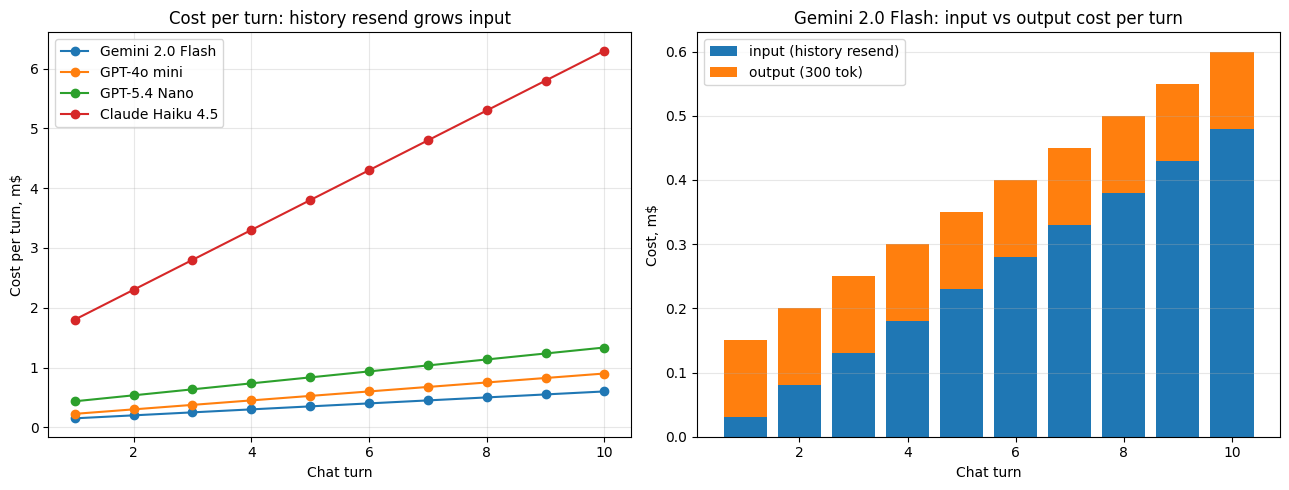

In [9]:
import matplotlib.pyplot as plt
import numpy as np

turns = np.arange(1, 11)
# Input tokens per turn: history grows linearly
inp = np.array([system + (t-1)*(user_msg+bot_msg) + user_msg for t in turns])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: cost per turn for each model
for name, per_turn in chat_results.items():
    axes[0].plot(turns, np.array(per_turn)*1000, marker='o', label=name)
axes[0].set_xlabel('Chat turn')
axes[0].set_ylabel('Cost per turn, m$')
axes[0].set_title('Cost per turn: history resend grows input')
axes[0].legend(); axes[0].grid(alpha=0.3)

# Right: input vs output split (Gemini 2.0 Flash)
pi, po = models["Gemini 2.0 Flash"]
cost_in  = inp / 1000 * pi * 1000
cost_out = np.full(10, bot_msg / 1000 * po * 1000)
axes[1].bar(turns, cost_in, label='input (history resend)')
axes[1].bar(turns, cost_out, bottom=cost_in, label='output (300 tok)')
axes[1].set_xlabel('Chat turn')
axes[1].set_ylabel('Cost, m$')
axes[1].set_title('Gemini 2.0 Flash: input vs output cost per turn')
axes[1].legend(); axes[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('chat_cost.png', dpi=150)
